In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import random
import numpy as np

In [21]:
y, sr = librosa.load("sample.wav", sr=None)

In [20]:
sr

44100

In [3]:
y.shape

(176400,)

In [4]:
1/sr * len(y)

4.0

In [34]:
FRAMESIZE=4096
HOP_LENGTH=512
def extract_amplitude_envelope(y, framesize=FRAMESIZE, hop_length=HOP_LENGTH):
    ae = []
    for i in range(0, len(y), hop_length):
        ae.append(max(y[i:i+framesize]))
    return np.array(ae)




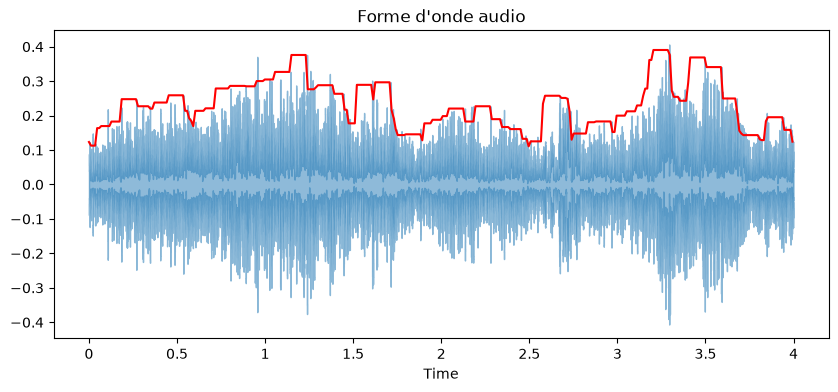

In [35]:
hop = 512
ae = extract_amplitude_envelope(y, hop_length=hop)
t = librosa.frames_to_time(range(0, ae.size), hop_length=hop, sr=sr)

len(ae)
fig, ax = plt.subplots(figsize=(10, 4))
librosa.display.waveshow(y, sr=sr, ax=ax, alpha=0.5)
plt.plot(t, ae, color="r")
plt.title('Forme d\'onde audio')
plt.show()


## Dataset loading

In [7]:
import pandas as pd
from pathlib import Path

In [8]:
metadata = pd.read_csv("UrbanSound8K/metadata/UrbanSound8K.csv")

In [9]:
metadata

,slice_file_name,fsID,start,end,salience,fold,classID,class
0,100032-3-0-0.wav,100032,0.000000,0.317551,1,5,3,dog_bark
1,100263-2-0-117.wav,100263,58.500000,62.500000,1,5,2,children_playing
2,100263-2-0-121.wav,100263,60.500000,64.500000,1,5,2,children_playing
3,100263-2-0-126.wav,100263,63.000000,67.000000,1,5,2,children_playing
4,100263-2-0-137.wav,100263,68.500000,72.500000,1,5,2,children_playing
...,...,...,...,...,...,...,...,...
8727,99812-1-2-0.wav,99812,159.522205,163.522205,2,7,1,car_horn
8728,99812-1-3-0.wav,99812,181.142431,183.284976,2,7,1,car_horn
8729,99812-1-4-0.wav,99812,242.691902,246.197885,2,7,1,car_horn
8730,99812-1-5-0.wav,99812,253.209850,255.741948,2,7,1,car_horn


In [10]:
def load_paths(df: pd.DataFrame, root_dir="UrbanSound8k/audio") -> pd.DataFrame:
    df['path'] = df.apply(lambda row: 
                          str(Path.cwd().resolve()/root_dir/f"fold{row['fold']}/{row['slice_file_name']}"), axis=1)
    return df

metadata = load_paths(metadata)


In [11]:
metadata = load_paths(metadata)

In [12]:
import os
import pandas as pd
from torch.utils.data import Dataset
class UrbanSound8kDataset(Dataset):
    def __init__(self, df):
        self.df = df
        
    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        path = self.df.iloc[idx]['path']
        label = self.df.iloc[idx]['class']
        signal, _ = librosa.load(path, sr=None)
        return (signal, label)


In [13]:
dataset = UrbanSound8kDataset(metadata)

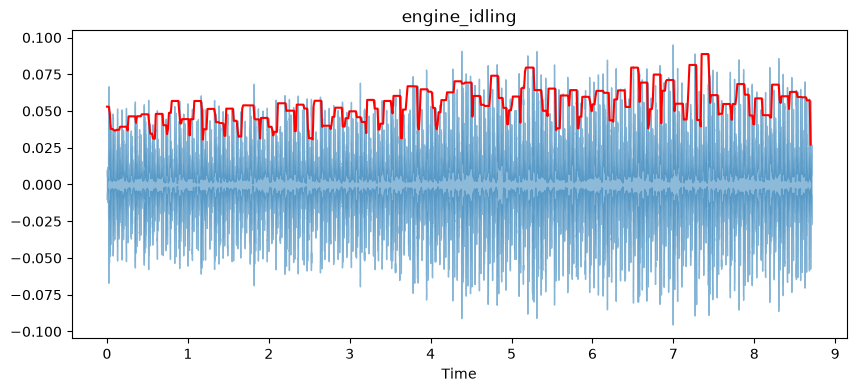

In [62]:
data = dataset[random.choice(range(len(dataset)))]
y, label = data
ae = extract_amplitude_envelope(y, hop_length=hop)
t = librosa.frames_to_time(range(0, ae.size), hop_length=hop, sr=sr)

len(ae)
fig, ax = plt.subplots(figsize=(10, 4))
librosa.display.waveshow(y, sr=sr, ax=ax, alpha=0.5)
plt.plot(t, ae, color="r")
plt.title(label)
plt.show()